# Modelo GRU

En este notebook se entrena una red neuronal GRU para clasificar géneros musicales utilizando los fragmentos de 3 segundos de cada canción.

Los fragmentos se agrupan por canción para que la red pueda analizarlos como una secuencia.

## Problema y objetivos

La empresa quiere identificar el género de una canción a partir de sus características de audio. La variable `id_genero` no es una etiqueta de sí o no, ni un valor numérico a estimar: toma 10 valores distintos y cada canción pertenece a una sola clase. El problema es de **clasificación supervisada multiclase**.

En este notebook el objetivo es entrenar una GRU que lea la secuencia de fragmentos de 3 segundos de cada canción y le asigne una de esas 10 clases. El modelo se ajusta solo con las canciones de entrenamiento; el conjunto de test se reserva para la evaluación. El resultado se mide con accuracy y F1 macro, para ver el acierto global y el rendimiento medio entre géneros.

## Selección de métricas y umbral

**Accuracy.** Hay 10 géneros y el mismo número de canciones en cada clase. Con ese reparto equilibrado, el porcentaje de aciertos resume el rendimiento global sin que una clase más frecuente lo distorsione.

**F1 macro.** Se calcula el F1 de cada género y se promedia dando el mismo peso a las 10 clases. Así, un género fácil de clasificar no compensa a otro que el modelo confunde. El F1 por clase del informe de clasificación muestra cuáles son esos géneros.

**Umbral de decisión.** El modelo devuelve una probabilidad para cada una de las 10 clases. La clase asignada es la de probabilidad más alta. No se exige una probabilidad mínima para aceptar la predicción: si la clase ganadora tiene, por ejemplo, 0,2 y el resto queda por debajo, esa clase se predice igualmente.

In [1]:
import numpy as np
import pandas as pd
import random
import tensorflow as tf
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Masking, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Carga y preparación de los datos

In [2]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

# Cargar los datos del archivo CSV en un DataFrame de pandas.
df_cancion_3s = pd.read_csv(DATOS / "df_cancion_3s.csv")

In [3]:
# DataFrame completo
display(df_cancion_3s)

,filename_3s,length_3s,chroma_stft_mean_3s,chroma_stft_var_3s,rms_mean_3s,rms_var_3s,spectral_centroid_mean_3s,spectral_centroid_var_3s,spectral_bandwidth_mean_3s,spectral_bandwidth_var_3s,...,label_3s,cancion_base,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,blues,blues.00000.wav,1,blues.00000.wav,138.0,744.01,1,1,1,1
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,blues,blues.00000.wav,1,blues.00000.wav,138.0,744.01,1,1,1,1
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,blues,blues.00000.wav,1,blues.00000.wav,138.0,744.01,1,1,1,1
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,blues,blues.00000.wav,1,blues.00000.wav,138.0,744.01,1,1,1,1
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,blues,blues.00000.wav,1,blues.00000.wav,138.0,744.01,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9985,rock.00099.5.wav,66149,0.349126,0.080515,0.050019,0.000097,1499.083005,164266.886443,1718.707215,85931.574523,...,rock,rock.00099.wav,1000,rock.00099.wav,144.0,4376.35,10,186,324,16
9986,rock.00099.6.wav,66149,0.372564,0.082626,0.057897,0.000088,1847.965128,281054.935973,1906.468492,99727.037054,...,rock,rock.00099.wav,1000,rock.00099.wav,144.0,4376.35,10,186,324,16
9987,rock.00099.7.wav,66149,0.347481,0.089019,0.052403,0.000701,1346.157659,662956.246325,1561.859087,138762.841945,...,rock,rock.00099.wav,1000,rock.00099.wav,144.0,4376.35,10,186,324,16
9988,rock.00099.8.wav,66149,0.387527,0.084815,0.066430,0.000320,2084.515327,203891.039161,2018.366254,22860.992562,...,rock,rock.00099.wav,1000,rock.00099.wav,144.0,4376.35,10,186,324,16


In [4]:
# Calcular el número de valores nulos por columna.
nulos_3s = df_cancion_3s.isna().sum()

display(nulos_3s[nulos_3s > 0].sort_values(ascending=False))

,0
duracion,180


In [5]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

# Cargar los ids de las canciones para los conjuntos de entrenamiento y prueba.
ids_train = pd.read_csv(DATOS / "ids_train.csv")['id_cancion']
ids_test = pd.read_csv(DATOS / "ids_test.csv")['id_cancion']

In [6]:
# Crear los DataFrames de entrenamiento y prueba usando los IDs cargados.
df_train = df_cancion_3s[df_cancion_3s['id_cancion'].isin(ids_train)].copy()
df_test = df_cancion_3s[df_cancion_3s['id_cancion'].isin(ids_test)].copy()

In [7]:
# Mostrar las dimensiones de los DataFrames de entrenamiento y prueba.
print("df_train:", df_train.shape)
print("df_test:", df_test.shape)

df_train: (7990, 69)
df_test: (2000, 69)


In [8]:
# Columnas disponibles en el DataFrame de entrenamiento.
print(df_train.columns.tolist())

['filename_3s', 'length_3s', 'chroma_stft_mean_3s', 'chroma_stft_var_3s', 'rms_mean_3s', 'rms_var_3s', 'spectral_centroid_mean_3s', 'spectral_centroid_var_3s', 'spectral_bandwidth_mean_3s', 'spectral_bandwidth_var_3s', 'rolloff_mean_3s', 'rolloff_var_3s', 'zero_crossing_rate_mean_3s', 'zero_crossing_rate_var_3s', 'harmony_mean_3s', 'harmony_var_3s', 'perceptr_mean_3s', 'perceptr_var_3s', 'tempo_3s', 'mfcc1_mean_3s', 'mfcc1_var_3s', 'mfcc2_mean_3s', 'mfcc2_var_3s', 'mfcc3_mean_3s', 'mfcc3_var_3s', 'mfcc4_mean_3s', 'mfcc4_var_3s', 'mfcc5_mean_3s', 'mfcc5_var_3s', 'mfcc6_mean_3s', 'mfcc6_var_3s', 'mfcc7_mean_3s', 'mfcc7_var_3s', 'mfcc8_mean_3s', 'mfcc8_var_3s', 'mfcc9_mean_3s', 'mfcc9_var_3s', 'mfcc10_mean_3s', 'mfcc10_var_3s', 'mfcc11_mean_3s', 'mfcc11_var_3s', 'mfcc12_mean_3s', 'mfcc12_var_3s', 'mfcc13_mean_3s', 'mfcc13_var_3s', 'mfcc14_mean_3s', 'mfcc14_var_3s', 'mfcc15_mean_3s', 'mfcc15_var_3s', 'mfcc16_mean_3s', 'mfcc16_var_3s', 'mfcc17_mean_3s', 'mfcc17_var_3s', 'mfcc18_mean_3s', 'm

# Selección de variables

Se eliminan las columnas identificativas, de texto y la variable objetivo. El modelo se entrena únicamente con variables numéricas.

In [9]:
# Estadísticas descriptivas y el número de valores únicos de la columna 'length_3s'.
print(df_train['length_3s'].describe())
print("\nValores únicos:", df_train['length_3s'].nunique())

count     7990.0
mean     66149.0
std          0.0
min      66149.0
25%      66149.0
50%      66149.0
75%      66149.0
max      66149.0
Name: length_3s, dtype: float64

Valores únicos: 1


Quitamos length_3s porque representa la misma duración en todos los fragmentos y, por tanto, no aporta información relevante para diferenciar géneros musicales. También se excluye duracion porque es una característica global de la canción y se repetiría en todos los pasos temporales de la secuencia, sin aportar información sobre la evolución del audio.

In [10]:
# Definir las columnas a excluir, luego crear los conjuntos X e Y para entrenamiento y prueba.
columnas_excluir = [
    'filename_3s',
    'length_3s',
    'label_3s',
    'cancion_base',
    'id_cancion',
    'cancion',
    'duracion',
    'coste',
    'id_genero',
    'id_disco',
    'id_autor',
    'id_discografica'
]

X_train = df_train.drop(columns=columnas_excluir)
X_test = df_test.drop(columns=columnas_excluir)

y_train = df_train['id_genero']
y_test = df_test['id_genero']

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7990, 57)
X_test: (2000, 57)
y_train: (7990,)
y_test: (2000,)


# Estandarización de los datos

Se estandarizan las variables para que todas trabajen en una escala similar antes de introducirlas en la red neuronal.

In [11]:
# Estandarizar las características de los conjuntos de entrenamiento y prueba utilizando StandardScaler.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (7990, 57)
X_test_scaled: (2000, 57)


In [12]:
# Convertir los arrays escalados de nuevo a DataFrames de pandas para preservar los índices y nombres de columna.
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    index=df_train.index,
    columns=X_train.columns
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    index=df_test.index,
    columns=X_test.columns
)

In [13]:
# Contar cuantos fragmentos tiene cada canción.
print(df_train.groupby('id_cancion').size().value_counts().sort_index())
print(df_test.groupby('id_cancion').size().value_counts().sort_index())

9      10
10    790
Name: count, dtype: int64
10    200
Name: count, dtype: int64


# Creación de las secuencias

Para utilizar la GRU se agrupan los fragmentos que pertenecen a una misma canción. De esta forma, cada canción pasa a estar representada por una secuencia de fragmentos en lugar de tratar cada fragmento de forma independiente.

In [14]:
# Agrupar los fragmentos de entrenamiento por canción
secuencias_train = []
y_train_cancion = []

for id_cancion, grupo in df_train.groupby('id_cancion', sort=False):

    secuencia = X_train_scaled_df.loc[grupo.index].to_numpy()

    secuencias_train.append(secuencia)

    y_train_cancion.append(grupo['id_genero'].iloc[0])


# Agrupar los fragmentos de test por canción
secuencias_test = []
y_test_cancion = []

for id_cancion, grupo in df_test.groupby('id_cancion', sort=False):

    secuencia = X_test_scaled_df.loc[grupo.index].to_numpy()

    secuencias_test.append(secuencia)

    y_test_cancion.append(grupo['id_genero'].iloc[0])

In [15]:
# Número de canciones en los conjuntos de entrenamiento y prueba.
print("Número de canciones train:", len(secuencias_train))
print("Número de canciones test:", len(secuencias_test))

print("Primera canción:", secuencias_train[0].shape)

Número de canciones train: 800
Número de canciones test: 200
Primera canción: (10, 57)


## Padding

La GRU necesita que todas las canciones tengan el mismo número de pasos temporales. La mayoría de canciones tiene 10 fragmentos de 3 segundos, pero 10 canciones del conjunto de entrenamiento tienen solo 9.

Para no eliminar esas canciones, añadimos un décimo fragmento de relleno. Este fragmento tendrá el valor -999 en todas sus características y posteriormente utilizaremos una capa Masking para que la GRU lo ignore durante el entrenamiento.

In [16]:

MAX_FRAGMENTOS = 10
VALOR_PADDING = -999.0

X_train_gru = pad_sequences(
    secuencias_train,
    maxlen=MAX_FRAGMENTOS,
    dtype='float32',
    padding='post',
    value=VALOR_PADDING
)

X_test_gru = pad_sequences(
    secuencias_test,
    maxlen=MAX_FRAGMENTOS,
    dtype='float32',
    padding='post',
    value=VALOR_PADDING
)

In [17]:
# Dimensiones de los conjuntos X transformados para la GRU.
print(X_train_gru.shape)
print(X_test_gru.shape)

(800, 10, 57)
(200, 10, 57)


Las etiquetas de género pasan de 1-10 a 0-9 para adaptarlas a las 10 clases de salida de la red neuronal.

In [18]:
# Convertir las etiquetas de género a arrays numpy y ajustar los valores para que estén en el rango de 0 a 9.
y_train_gru = np.array(y_train_cancion, dtype=np.int32) - 1
y_test_gru = np.array(y_test_cancion, dtype=np.int32) - 1

In [19]:
print("X_train_gru:", X_train_gru.shape)
print("y_train_gru:", y_train_gru.shape)

print("X_test_gru:", X_test_gru.shape)
print("y_test_gru:", y_test_gru.shape)

print("Clases:", np.unique(y_train_gru))

X_train_gru: (800, 10, 57)
y_train_gru: (800,)
X_test_gru: (200, 10, 57)
y_test_gru: (200,)
Clases: [0 1 2 3 4 5 6 7 8 9]


# Construcción del modelo

Se construye la red GRU para analizar los fragmentos de cada canción como una secuencia.

La capa Masking  permite ignorar el padding, la GRU analiza la información temporal de los fragmentos, Dropout ayuda a reducir el sobreajuste y la última capa devuelve una probabilidad para cada uno de los 10 géneros.

In [20]:

model = Sequential([
    Input(shape=(10, 57)),
    Masking(mask_value=-999.0),
    GRU(64),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 10, 57)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        23,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,266 (94.79 KB)

 Trainable params: 24,266 (94.79 KB)

 Non-trainable params: 0 (0.00 B)

El modelo trabaja con secuencias de 10 fragmentos y 57 características por fragmento. La capa GRU utiliza 64 unidades y la salida está formada por 10 neuronas, una por cada género.

# División de entrenamiento y validación

Se reserva un 20% de las canciones de entrenamiento para validación. Sin utilizar todavía el conjunto de test.

In [21]:
# Dividimos el conjunto de entrenamiento en train y validación
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_gru,
    y_train_gru,
    test_size=0.2,
    random_state=42,
    stratify=y_train_gru
)

print("Train:", X_train_final.shape, y_train_final.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test_gru.shape, y_test_gru.shape)

Train: (640, 10, 57) (640,)
Validación: (160, 10, 57) (160,)
Test: (200, 10, 57) (200,)


# Compilación del modelo

Se utiliza Adam como optimizador porque ajusta automáticamente el ritmo de aprendizaje de los pesos.

Se utiliza sparse_categorical_crossentropy porque tenemos un problema de 10 clases y las etiquetas están representadas directamente como números del 0 al 9, sin necesidad de convertirlas a one-hot encoding.

In [22]:
# Compilamos el modelo indicando cómo aprenderá y qué métrica
# queremos observar durante el entrenamiento
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Se utiliza early_stopping para detener el entrenamiento cuando la validación deja de mejorar y evitar seguir sobreajustando el modelo.

In [23]:
# Detiene el entrenamiento si la pérdida de validación deja de mejorar
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Entrenamiento del modelo

In [24]:
history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.2719 - loss: 2.0173 - val_accuracy: 0.4625 - val_loss: 1.6210
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4719 - loss: 1.5054 - val_accuracy: 0.5250 - val_loss: 1.3751
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5594 - loss: 1.2701 - val_accuracy: 0.5750 - val_loss: 1.2333
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.6313 - loss: 1.1068 - val_accuracy: 0.6125 - val_loss: 1.1224
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6547 - loss: 1.0065 - val_accuracy: 0.6438 - val_loss: 1.0325
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7156 - loss: 0.8804 - val_accuracy: 0.6500 - val_loss: 0.9650
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7484 - loss: 0.8007 - val_accuracy: 0.6812 - val_loss: 0.9039
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7625 - loss: 0.6949 - val_accuracy: 0.700

In [25]:
print("Epoch entrenadas:", len(history.history['loss']))

print("Última accuracy train:", history.history['accuracy'][-1])
print("Última accuracy validación:", history.history['val_accuracy'][-1])

print("Mejor val_loss:", min(history.history['val_loss']))

Epoch entrenadas: 23
Última accuracy train: 0.973437488079071
Última accuracy validación: 0.7250000238418579
Mejor val_loss: 0.7132574915885925


El entrenamiento se detuvo automáticamente tras 23 epochs mediante EarlyStopping. Se observa una diferencia entre el rendimiento de entrenamiento y validación, indicando cierto sobreajuste

# Evaluación del modelo

Se realizan las predicciones sobre las 200 canciones reservadas para test.

In [26]:
# Probabilidades predichas para las canciones de test
y_pred_prob = model.predict(X_test_gru)

# Género con mayor probabilidad
y_pred = np.argmax(y_pred_prob, axis=1)

print("Predicciones:", y_pred.shape)
print("Valores predichos:", np.unique(y_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Predicciones: (200,)
Valores predichos: [0 1 2 3 4 5 6 7 8 9]


In [27]:
# Recuperar las etiquetas originales de género: 0-9 -> 1-10
y_test_original = y_test_gru + 1
y_pred_original = y_pred + 1

accuracy_gru = accuracy_score(y_test_original, y_pred_original)

print(f"Accuracy GRU: {accuracy_gru:.4f}")
print()
print(classification_report(
    y_test_original,
    y_pred_original,
    labels=np.arange(1, 11)
))

Accuracy GRU: 0.7200

              precision    recall  f1-score   support

           1       0.74      0.70      0.72        20
           2       0.83      1.00      0.91        20
           3       0.73      0.80      0.76        20
           4       0.75      0.45      0.56        20
           5       0.68      0.75      0.71        20
           6       0.88      0.75      0.81        20
           7       1.00      0.80      0.89        20
           8       0.71      0.75      0.73        20
           9       0.52      0.70      0.60        20
          10       0.50      0.50      0.50        20

    accuracy                           0.72       200
   macro avg       0.73      0.72      0.72       200
weighted avg       0.73      0.72      0.72       200



El modelo obtiene un accuracy del 72%. El rendimiento varía entre clases, siendo las clases 4 y 10 las que presentan mayores dificultades de clasificación.

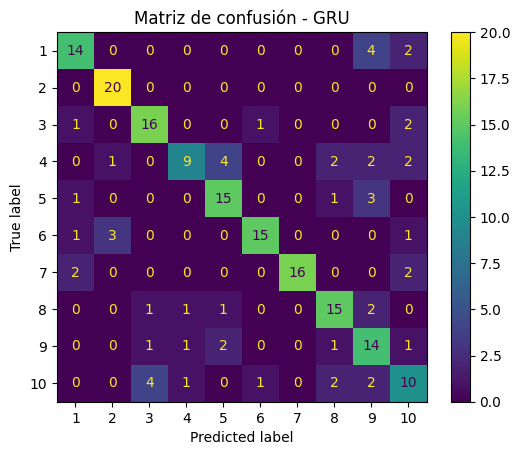

In [28]:
# La matriz de confusión permite visualizar los aciertos y errores del modelo
# y comprobar qué clases tiende a confundir la GRU entre sí.

# Matriz de confusión con las etiquetas originales 1-10

matriz_confusion = confusion_matrix(
    y_test_original,
    y_pred_original,
    labels=np.arange(1, 11)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=np.arange(1, 11)
)

disp.plot()
plt.title("Matriz de confusión - GRU")
plt.show()

La clase 2 es la que mejor se clasifica, con las 20 canciones correctamente identificadas. Las clases 4 y 10 presentan un mayor número de errores y se confunden con varias clases diferentes.

## Evolución del entrenamiento

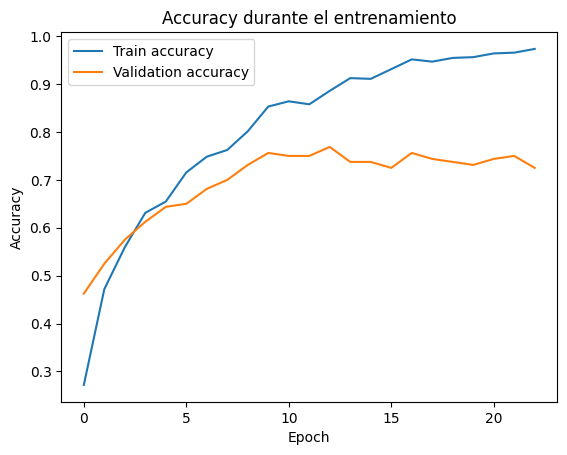

In [29]:
# Evolución de la precisión durante el entrenamiento
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')

plt.title('Accuracy durante el entrenamiento')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

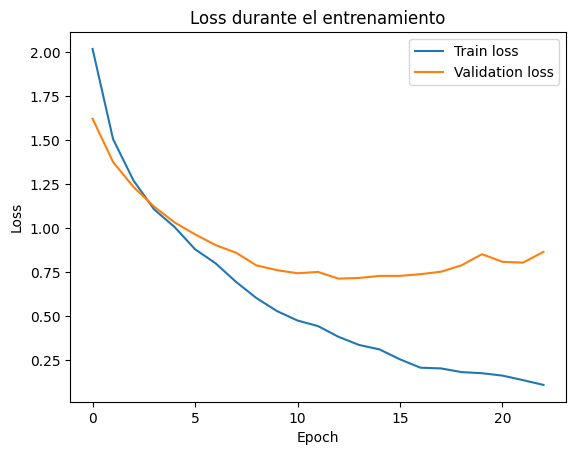

In [30]:
# Evolución de la pérdida durante el entrenamiento
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.title('Loss durante el entrenamiento')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Las curvas muestran una mejora conjunta durante las primeras epochs. Posteriormente, la pérdida de entrenamiento continúa disminuyendo mientras que la pérdida de validación se estabiliza y comienza a aumentar, evidenciando sobreajuste. El uso de EarlyStopping permite detener el entrenamiento y recuperar los pesos correspondientes al mejor rendimiento de validación.

# Conclusiones

La GRU se ha construido para clasificar el género musical a partir de secuencias de fragmentos de 3 segundos de cada canción.

El modelo obtiene un accuracy del 72% sobre el conjunto de test. Durante el entrenamiento se observa cierto sobreajuste, por lo que se utilizan Dropout y EarlyStopping para limitarlo.

Como posibles mejoras se podrían probar otros valores de Dropout, modificar el número de unidades de la GRU o trabajar con más datos de entrenamiento.